<div style="background:linear-gradient(90deg,#2193b0,#6dd5ed);padding:26px;border-radius:14px;color:white">
<h4 style="margin:0;opacity:0.9">🧬 AI GENESIS · THE STORY OF AI, ONE ALGORITHM AT A TIME</h4>
<h1 style="margin:6px 0 4px 0">Uninformed Search (1950s)</h1>
<p style="margin:0">BFS · DFS · Uniform-Cost · Depth-Limited · Iterative Deepening · Bidirectional</p>
</div>

<br>

| 🪪 Quick card | |
|---|---|
| **Years** | 1950s (BFS: Moore 1959 · Uniform-Cost: Dijkstra 1956) |
| **Also by** | Trémaux (DFS, 19th century), Pohl (Bidirectional, 1971), Korf (Iterative Deepening, 1985) |
| **Family** | Symbolic AI → Search & Planning → **Uninformed (blind) search** |
| **Learns from data?** | ❌ No. It explores possibilities |
| **Needs** | A start state, actions, and a goal test |
| **Test problems** | A road map of Romania, the 8-puzzle, and a maze |
| **Difficulty** | ⭐⭐ Beginner |

### 🎯 What you will learn in this notebook
1. Why **search** was the very first big idea in AI
2. How to describe any problem as *states, actions and a goal*
3. Six blind-search algorithms, each built **from scratch** and run on real problems
4. Which one is optimal, which uses less memory, which is fastest, **measured with real numbers**
5. How the **8-puzzle** shows the cost of blind search (and why we will need heuristics next)

## 📖 Part 1: The story

Before machine learning, the first AI researchers believed **thinking = searching**.

- In **1956**, at the Dartmouth workshop where the term *Artificial Intelligence* was born, Allen Newell, Herbert Simon and Cliff Shaw showed the **Logic Theorist**, a program that proved mathematical theorems by **searching through possible proof steps**.
- In **1957** they built the **General Problem Solver**, using the same idea for many puzzles.

The recipe that came out of this era is still taught today:

> **Describe the problem as a graph of *states*, then search for a path from the *start state* to a *goal state*.**

### 🙈 What does "uninformed" mean?
These algorithms know **nothing** about how close a state is to the goal. They only know how to generate neighbours and recognise the goal. That is why they are also called **blind search**. (Next in the story: *informed* search such as A\*, which uses hints.)

### 👤 Who invented what

| Algorithm | Idea | Who and when |
|---|---|---|
| **DFS** | Go as deep as possible first | Charles Pierre Trémaux used it to solve mazes (19th century) |
| **UCS** | Always expand the cheapest path first | Edsger Dijkstra, conceived 1956, published 1959 |
| **BFS** | Explore level by level | Konrad Zuse (1945, unpublished); Edward F. Moore (1959, mazes) |
| **Bidirectional** | Search from both ends | Ira Pohl (1971) |
| **Iterative Deepening** | Repeat depth-limited DFS with growing limits | Richard Korf (1985) |

### 🗺️ Where this fits
```
Logic Theorist (1956) → Uninformed Search → Informed Search: A* (1968) → Game Search: Minimax & Alpha-Beta → Constraint Satisfaction
```

## 🧠 Part 2: The ideas in plain words

You lost your keys in a big house. Different ways to look:

| Algorithm | In the house | Data structure |
|---|---|---|
| **BFS** | Check every room next to you, then every room two doors away, then three... | Queue (first in, first out) |
| **DFS** | Pick a door, keep going through doors as deep as you can, go back only when stuck | Stack (last in, first out) |
| **UCS** | Always continue from the place that cost you the least effort so far | Priority queue |
| **Depth-Limited** | Like DFS, but never go more than *L* doors deep | Stack + limit |
| **Iterative Deepening** | Try limit 0, then 1, then 2, ... until the keys appear | Repeated DFS |
| **Bidirectional** | Your friend starts from where the keys *must* be; you meet in the middle | Two queues |

### 📏 How do we judge a search algorithm?
- **Complete**: does it always find a solution if one exists?
- **Optimal**: is the solution it finds the cheapest?
- **Time**: how many nodes does it expand?
- **Space**: how many nodes must it keep in memory?

Let `b` = branching factor (choices per step), `d` = depth of the shallowest goal, `m` = maximum depth, `l` = depth limit.

| | BFS | DFS | UCS | DLS | IDDFS | Bidirectional |
|---|---|---|---|---|---|---|
| **Complete?** | ✅ | ⚠️ only with a visited set | ✅ | ❌ | ✅ | ✅ |
| **Optimal?** | ✅ if all steps cost the same | ❌ | ✅ | ❌ | ✅ if all steps cost the same | ✅ if all steps cost the same |
| **Time** | O(bᵈ) | O(bᵐ) | about O(bᵈ) or more | O(bˡ) | O(bᵈ) | O(bᵈ/²) |
| **Space** | O(bᵈ) | O(b·m) | O(bᵈ) or more | O(b·l) | O(b·d) | O(bᵈ/²) |

## 🟣 Step 1: Import the libraries
> 💡 Python's standard library gives us what we need: `deque` (queue), `heapq` (priority queue) and `time`.

In [1]:
# Import the libraries we need
import heapq
import time
import itertools
import random
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, Rectangle

# Styling and a colour palette used across the notebook
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, CYAN, GREEN, ORANGE, RED, PURPLE, GREY, DARK = "#2193b0", "#6dd5ed", "#27ae60", "#f39c12", "#e74c3c", "#8e54e9", "#7f8c8d", "#2c3e50"

print("✅ Libraries ready!")

✅ Libraries ready!


## 🌳 Step 2: BFS vs DFS: the order of visiting
> 💡 Same tree, two different orders. The numbers show **when** each node is visited.
> BFS sweeps level by level. DFS dives down the left side first.

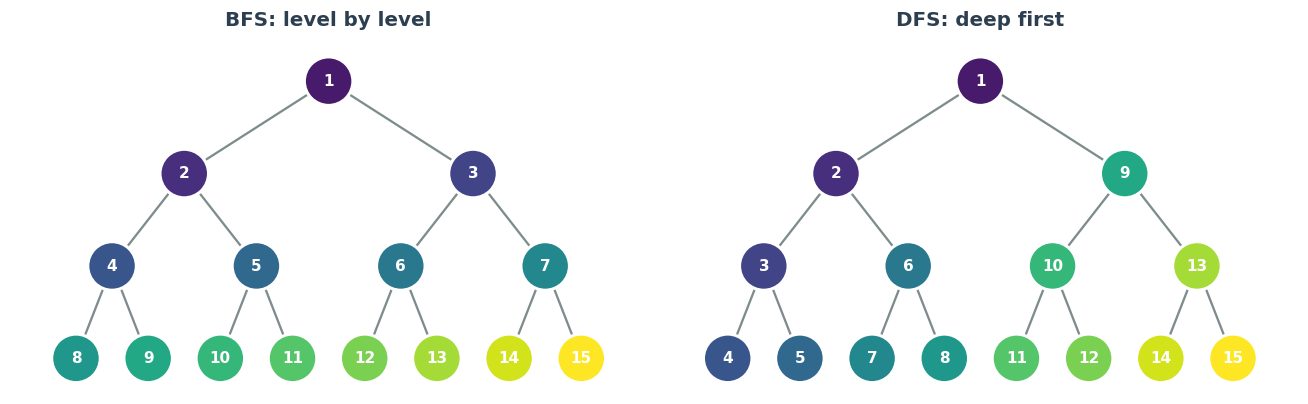

In [2]:
# Draw one tree twice: numbered by BFS order and by DFS order
depth = 3                                              # levels 0..3 → 15 nodes
nodes = list(range(1, 2 ** (depth + 1)))               # heap numbering: children of k are 2k and 2k+1

bfs_order = {k: k for k in nodes}                      # level order is simply 1, 2, 3, ...
dfs_order, counter = {}, [0]
def preorder(k):
    if k > nodes[-1]:
        return
    counter[0] += 1
    dfs_order[k] = counter[0]
    preorder(2 * k); preorder(2 * k + 1)
preorder(1)

def position(k):
    level = k.bit_length() - 1
    index = k - 2 ** level
    return (index + 0.5) / 2 ** level * 10, -level * 1.6

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, order, title in [(axes[0], bfs_order, "BFS: level by level"), (axes[1], dfs_order, "DFS: deep first")]:
    for k in nodes:
        if 2 * k <= nodes[-1]:
            for child in (2 * k, 2 * k + 1):
                (x1, y1), (x2, y2) = position(k), position(child)
                ax.plot([x1, x2], [y1, y2], color=GREY, lw=1.5, zorder=1)
    for k in nodes:
        x, y = position(k)
        ax.add_patch(Circle((x, y), 0.42, color=plt.cm.viridis(order[k] / len(nodes)), ec="white", lw=2, zorder=3))
        ax.text(x, y, str(order[k]), ha="center", va="center", color="white", fontweight="bold", fontsize=10, zorder=4)
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-5.4, 0.8); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, color=DARK, fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

## 🧩 Step 3: Describe a problem the AI way
> 💡 Every search problem has the same four parts:
> 1. **Start state**
> 2. **Actions** (which neighbours can I move to, and at what cost?)
> 3. **Goal test** (am I done?)
> 4. **Path cost** (sum of step costs)
>
> We write one small base class, then three concrete problems. The algorithms we build later work on **any** of them without changes.

In [3]:
# A general search problem + three concrete problems
class Problem:
    '''Base class: subclasses must provide successors(state) -> list of (action, next_state, step_cost).'''
    def __init__(self, start, goal):
        self.start, self.goal = start, goal
    def is_goal(self, state):
        return state == self.goal
    def successors(self, state):
        raise NotImplementedError


class MapProblem(Problem):
    '''Find a route on a road map. Step cost = distance in km.'''
    def __init__(self, roads, start, goal):
        super().__init__(start, goal)
        self.roads = roads
    def successors(self, city):
        return [(f"go to {n}", n, km) for n, km in self.roads[city].items()]


class PuzzleProblem(Problem):
    '''The 8-puzzle. A state is a tuple of 9 numbers, 0 is the blank. Every move costs 1.'''
    MOVES = [("Up", -1, 0), ("Down", 1, 0), ("Left", 0, -1), ("Right", 0, 1)]
    def successors(self, state):
        blank = state.index(0)
        r, c = divmod(blank, 3)
        result = []
        for name, dr, dc in self.MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < 3 and 0 <= nc < 3:
                other = nr * 3 + nc
                s = list(state)
                s[blank], s[other] = s[other], s[blank]
                result.append((name, tuple(s), 1))
        return result


class GridProblem(Problem):
    '''A maze on a square grid. A state is (row, col). Every step costs 1.'''
    MOVES = [("Up", -1, 0), ("Right", 0, 1), ("Down", 1, 0), ("Left", 0, -1)]
    def __init__(self, size, walls, start, goal):
        super().__init__(start, goal)
        self.size, self.walls = size, walls
    def successors(self, state):
        r, c = state
        result = []
        for name, dr, dc in self.MOVES:
            nr, nc = r + dr, c + dc
            if 0 <= nr < self.size and 0 <= nc < self.size and (nr, nc) not in self.walls:
                result.append((name, (nr, nc), 1))
        return result

print("✅ Problem classes created!")

✅ Problem classes created!


## 🇷🇴 Step 4: The map of Romania
> 💡 A classic AI test problem. Each number is a road length in km. We want the way from **Arad** to **Bucharest**.
> Notice the shortest route in **number of towns** is not the shortest in **kilometres**. This difference will separate BFS from UCS.

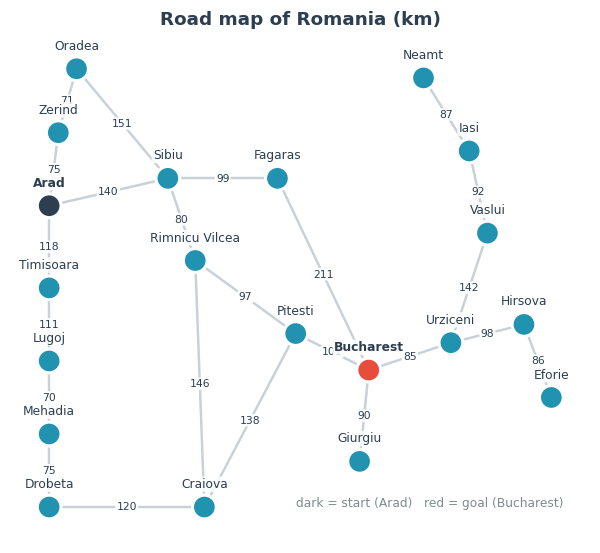

In [4]:
# The road map of Romania (distances in km)
edges = [("Arad", "Zerind", 75), ("Arad", "Sibiu", 140), ("Arad", "Timisoara", 118),
         ("Zerind", "Oradea", 71), ("Oradea", "Sibiu", 151), ("Timisoara", "Lugoj", 111),
         ("Lugoj", "Mehadia", 70), ("Mehadia", "Drobeta", 75), ("Drobeta", "Craiova", 120),
         ("Craiova", "Rimnicu Vilcea", 146), ("Craiova", "Pitesti", 138),
         ("Sibiu", "Fagaras", 99), ("Sibiu", "Rimnicu Vilcea", 80), ("Rimnicu Vilcea", "Pitesti", 97),
         ("Fagaras", "Bucharest", 211), ("Pitesti", "Bucharest", 101), ("Bucharest", "Giurgiu", 90),
         ("Bucharest", "Urziceni", 85), ("Urziceni", "Hirsova", 98), ("Hirsova", "Eforie", 86),
         ("Urziceni", "Vaslui", 142), ("Vaslui", "Iasi", 92), ("Iasi", "Neamt", 87)]

roads = {}
for a, b, km in edges:
    roads.setdefault(a, {})[b] = km
    roads.setdefault(b, {})[a] = km

# Rough positions just for drawing
pos = {"Oradea": (90, 450), "Zerind": (70, 380), "Arad": (60, 300), "Timisoara": (60, 210), "Lugoj": (60, 130),
       "Mehadia": (60, 50), "Drobeta": (60, -30), "Craiova": (230, -30), "Sibiu": (190, 330),
       "Rimnicu Vilcea": (220, 240), "Fagaras": (310, 330), "Pitesti": (330, 160), "Bucharest": (410, 120),
       "Giurgiu": (400, 20), "Urziceni": (500, 150), "Hirsova": (580, 170), "Eforie": (610, 90),
       "Vaslui": (540, 270), "Iasi": (520, 360), "Neamt": (470, 440)}

def draw_map(path=None, title="", color=RED):
    fig, ax = plt.subplots(figsize=(8.5, 6))
    on_path = set(zip(path[:-1], path[1:])) | set(zip(path[1:], path[:-1])) if path else set()
    for a, b, km in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        hot = (a, b) in on_path
        ax.plot([x1, x2], [y1, y2], color=color if hot else "#c8d0d8", lw=4.5 if hot else 1.6, zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(km), fontsize=7, color=DARK, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9), zorder=2)
    for city, (x, y) in pos.items():
        special = city in ("Arad", "Bucharest")
        in_path = bool(path) and city in path
        ax.add_patch(Circle((x, y), 13, color=DARK if city == "Arad" else RED if city == "Bucharest"
                            else color if in_path else BLUE, ec="white", lw=2, zorder=3))
        ax.text(x, y + 25, city, fontsize=8, ha="center", va="center", color=DARK,
                fontweight="bold" if (special or in_path) else None,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.85), zorder=4)
    ax.text(330, -30, "dark = start (Arad)   red = goal (Bucharest)", fontsize=8, color=GREY)
    ax.set_title(title, color=DARK, fontweight="bold")
    ax.set_aspect("equal"); ax.axis("off")
    plt.show()

draw_map(title="Road map of Romania (km)")

## 🛠️ Step 5: A few helpers
> 💡 Every algorithm returns the same kind of answer: the **path**, its **cost**, how many nodes it **expanded** (time), and the **peak number of nodes it stored** (memory). This lets us compare them fairly.

In [5]:
# Helpers shared by all search algorithms
def reconstruct(parent, goal_state):
    '''Follow the parent links back from the goal to the start.'''
    path, s = [], goal_state
    while s is not None:
        path.append(s)
        s = parent[s]
    return path[::-1]

def path_cost(problem, path):
    total = 0
    for a, b in zip(path[:-1], path[1:]):
        total += min(cost for _, n, cost in problem.successors(a) if n == b)
    return total

def finish(name, problem, path, expanded, memory, t0, order=None):
    '''Pack everything into one result dictionary.'''
    return {"algorithm": name, "found": path is not None, "path": path,
            "steps": len(path) - 1 if path else None,
            "cost": path_cost(problem, path) if path else None,
            "expanded": expanded, "memory": memory,
            "ms": round((time.perf_counter() - t0) * 1000, 1), "order": order or []}

def results_table(results):
    return pd.DataFrame([{k: r[k] for k in ["algorithm", "found", "steps", "cost", "expanded", "memory", "ms"]}
                         for r in results])

print("✅ Helpers ready!")

✅ Helpers ready!


## 🌊 Step 6: Breadth-First Search (BFS)
> 💡 Use a **queue**. Take the oldest node, add its unseen neighbours to the back. The search spreads like ripples in a pond, so it finds the goal with the **fewest steps**.
> It keeps a `parent` dictionary: it both remembers where we came from (to rebuild the path) and which states were already seen.

In [6]:
# Breadth-First Search
def bfs(problem):
    t0 = time.perf_counter()
    if problem.is_goal(problem.start):
        return finish("BFS", problem, [problem.start], 0, 1, t0)
    frontier = deque([problem.start])          # the queue
    parent = {problem.start: None}             # seen states and where we came from
    order, expanded = [], 0
    while frontier:
        state = frontier.popleft()             # oldest first (FIFO)
        order.append(state); expanded += 1
        for _, nxt, _ in problem.successors(state):
            if nxt not in parent:
                parent[nxt] = state
                if problem.is_goal(nxt):       # stop as soon as the goal is generated
                    return finish("BFS", problem, reconstruct(parent, nxt), expanded, len(parent), t0, order)
                frontier.append(nxt)
    return finish("BFS", problem, None, expanded, len(parent), t0, order)

map_problem = MapProblem(roads, "Arad", "Bucharest")
r_bfs = bfs(map_problem)
print("BFS route:", " → ".join(r_bfs["path"]))
print(f"Towns visited: {r_bfs['steps']} steps | distance: {r_bfs['cost']} km | nodes expanded: {r_bfs['expanded']}")

BFS route: Arad → Sibiu → Fagaras → Bucharest
Towns visited: 3 steps | distance: 450 km | nodes expanded: 6


## 🕳️ Step 7: Depth-First Search (DFS)
> 💡 Use a **stack**. Take the newest node, push its neighbours on top. The search dives deep along one path and backs up only when stuck.
> It uses very little memory, but the first path it finds can be **very long**. We keep a `explored` set so it never walks in circles.

In [7]:
# Depth-First Search (graph search with an explored set)
def dfs(problem):
    t0 = time.perf_counter()
    stack = [(problem.start, None)]            # the stack holds (state, parent)
    explored, parent = set(), {}
    order, expanded, peak = [], 0, 1
    while stack:
        state, par = stack.pop()               # newest first (LIFO)
        if state in explored:
            continue
        explored.add(state); parent[state] = par
        order.append(state); expanded += 1
        if problem.is_goal(state):
            return finish("DFS", problem, reconstruct(parent, state), expanded, peak, t0, order)
        for _, nxt, _ in reversed(problem.successors(state)):   # reversed so the first neighbour is explored first
            if nxt not in explored:
                stack.append((nxt, state))
        peak = max(peak, len(stack) + len(explored))
    return finish("DFS", problem, None, expanded, peak, t0, order)

r_dfs = dfs(map_problem)
print("DFS route:", " → ".join(r_dfs["path"]))
print(f"Steps: {r_dfs['steps']} | distance: {r_dfs['cost']} km | nodes expanded: {r_dfs['expanded']}")

DFS route: Arad → Zerind → Oradea → Sibiu → Fagaras → Bucharest
Steps: 5 | distance: 607 km | nodes expanded: 6


## 💰 Step 8: Uniform-Cost Search (UCS), Dijkstra's idea
> 💡 Use a **priority queue** ordered by the **total cost so far**. Always expand the cheapest path.
> Unlike BFS (which counts steps), UCS counts the real cost, so it finds the **cheapest** route even when roads have different lengths.
> Note: UCS tests for the goal when a node is **taken out** of the queue, not when it is added. That is what guarantees the cheapest path.

In [8]:
# Uniform-Cost Search
def ucs(problem):
    t0 = time.perf_counter()
    counter = itertools.count()                # tie-breaker so the heap never compares states
    heap = [(0, next(counter), problem.start, None)]
    explored, parent = set(), {}
    order, expanded, peak = [], 0, 1
    while heap:
        cost, _, state, par = heapq.heappop(heap)    # the cheapest path so far
        if state in explored:
            continue
        explored.add(state); parent[state] = par
        order.append(state); expanded += 1
        if problem.is_goal(state):
            return finish("UCS", problem, reconstruct(parent, state), expanded, peak, t0, order)
        for _, nxt, step in problem.successors(state):
            if nxt not in explored:
                heapq.heappush(heap, (cost + step, next(counter), nxt, state))
        peak = max(peak, len(heap) + len(explored))
    return finish("UCS", problem, None, expanded, peak, t0, order)

r_ucs = ucs(map_problem)
print("UCS route:", " → ".join(r_ucs["path"]))
print(f"Steps: {r_ucs['steps']} | distance: {r_ucs['cost']} km | nodes expanded: {r_ucs['expanded']}")

UCS route: Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest
Steps: 4 | distance: 418 km | nodes expanded: 13


## 🏁 Step 9: Who found the best route?
> 💡 Same map, same start and goal, three different answers. Look at the **cost** column: only UCS finds the cheapest route (418 km).
> BFS found the route with the fewest towns, but it is longer in kilometres. DFS took a detour.

algorithm  steps  distance (km)  expanded                                                route
      BFS      3            450         6                   Arad → Sibiu → Fagaras → Bucharest
      DFS      5            607         6 Arad → Zerind → Oradea → Sibiu → Fagaras → Bucharest
      UCS      4            418        13  Arad → Sibiu → Rimnicu Vilcea → Pitesti → Bucharest


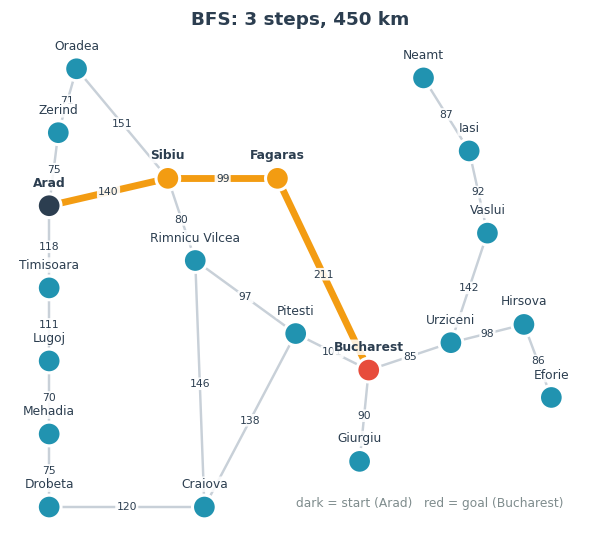

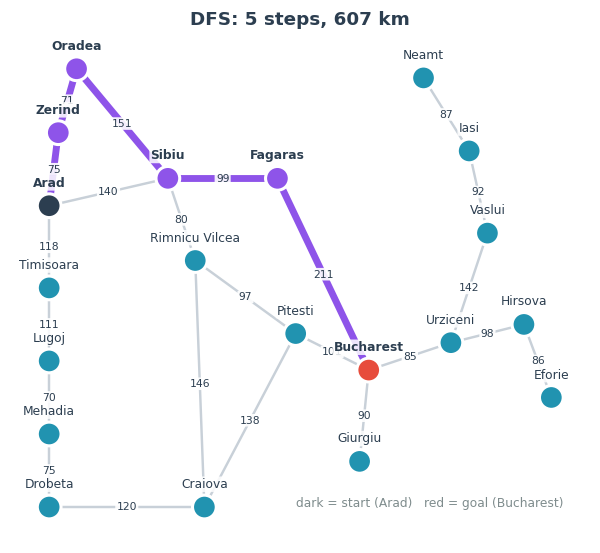

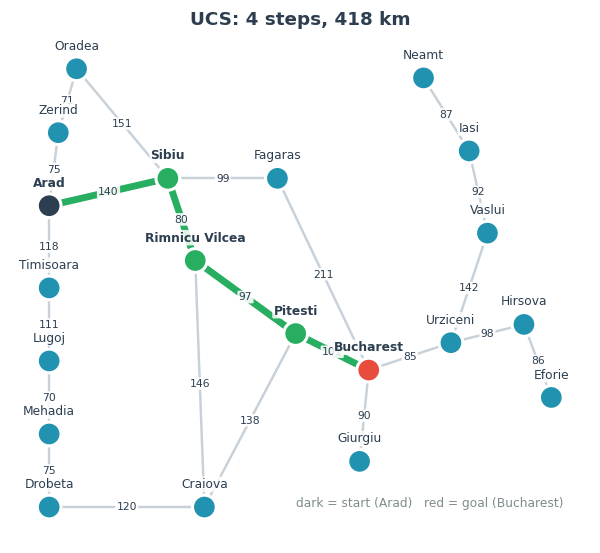

In [9]:
# Compare BFS, DFS and UCS on the Romania map
table = results_table([r_bfs, r_dfs, r_ucs])
table["route"] = [" → ".join(r["path"]) for r in (r_bfs, r_dfs, r_ucs)]
display_table = table[["algorithm", "steps", "cost", "expanded", "route"]].rename(columns={"cost": "distance (km)"})
print(display_table.to_string(index=False))

for r, color in [(r_bfs, ORANGE), (r_dfs, PURPLE), (r_ucs, GREEN)]:
    draw_map(r["path"], f"{r['algorithm']}: {r['steps']} steps, {r['cost']} km", color)

## ✋ Step 10: Depth-Limited Search (DLS)
> 💡 DFS has a danger: on very deep (or endless) problems it can dive forever. The fix is simple: **never go deeper than a limit `L`**.
> It returns `"cutoff"` if the limit stopped it, which is different from "no solution exists".
> Here we avoid walking in circles by only checking the **current path** (this keeps memory tiny).

In [10]:
# Depth-Limited Search
def depth_limited(problem, limit):
    stats = {"expanded": 0, "peak": 0}

    def recurse(state, path, depth):
        stats["expanded"] += 1
        stats["peak"] = max(stats["peak"], depth + 1)       # nodes on the current path = memory used
        if problem.is_goal(state):
            return list(path)
        if depth == limit:
            return "cutoff"
        cut = False
        for _, nxt, _ in problem.successors(state):
            if nxt in path:                                 # don't walk in a circle
                continue
            path.append(nxt)
            result = recurse(nxt, path, depth + 1)
            path.pop()
            if result == "cutoff":
                cut = True
            elif result is not None:
                return result
        return "cutoff" if cut else None

    result = recurse(problem.start, [problem.start], 0)
    return result, stats

for limit in [1, 2, 3, 4]:
    result, stats = depth_limited(map_problem, limit)
    shown = "cutoff (limit too small)" if result == "cutoff" else " → ".join(result)
    print(f"limit = {limit}: {shown}   [nodes expanded: {stats['expanded']}]")

limit = 1: cutoff (limit too small)   [nodes expanded: 4]
limit = 2: cutoff (limit too small)   [nodes expanded: 9]
limit = 3: Arad → Sibiu → Fagaras → Bucharest   [nodes expanded: 9]
limit = 4: Arad → Sibiu → Fagaras → Bucharest   [nodes expanded: 11]


## 🔁 Step 11: Iterative Deepening DFS (IDDFS)
> 💡 The best of both worlds: run DLS with limit **0, 1, 2, 3, ...** until the goal appears.
> - Like BFS, it finds the **shallowest** goal.
> - Like DFS, it uses **very little memory**.
> Repeating the upper levels looks wasteful, but the last level is so much bigger than all the others that the repetition costs little.

In [11]:
# Iterative Deepening DFS
def iddfs(problem, max_limit=40):
    t0 = time.perf_counter()
    total_expanded, peak = 0, 0
    for limit in range(max_limit + 1):
        result, stats = depth_limited(problem, limit)
        total_expanded += stats["expanded"]
        peak = max(peak, stats["peak"])
        if result != "cutoff":                              # found the goal (or proved there is none)
            return finish("IDDFS", problem, result, total_expanded, peak, t0)
    return finish("IDDFS", problem, None, total_expanded, peak, t0)

r_iddfs = iddfs(map_problem)
print("IDDFS route:", " → ".join(r_iddfs["path"]))
print(f"Steps: {r_iddfs['steps']} | distance: {r_iddfs['cost']} km | nodes expanded (all rounds): {r_iddfs['expanded']}")

IDDFS route: Arad → Sibiu → Fagaras → Bucharest
Steps: 3 | distance: 450 km | nodes expanded (all rounds): 23


## ↔️ Step 12: Bidirectional Search
> 💡 Run **two BFS searches at once**: one forward from the start, one backward from the goal. When they touch, the path is complete.
> Two small circles cover far less than one huge circle: `b^(d/2) + b^(d/2)` is much smaller than `b^d`.
> It needs actions that can be reversed (like moving a tile or walking a road). We expand one whole level at a time from the smaller side.

In [12]:
# Bidirectional BFS (for problems where every step costs the same)
def bidirectional(problem):
    t0 = time.perf_counter()
    start, goal = problem.start, problem.goal
    if start == goal:
        return finish("Bidirectional", problem, [start], 0, 1, t0)
    parent_f, parent_b = {start: None}, {goal: None}
    dist_f, dist_b = {start: 0}, {goal: 0}
    front_f, front_b = deque([start]), deque([goal])
    order, expanded = [], 0

    def expand_layer(frontier, parent, dist, other_dist):
        nonlocal expanded
        new, best = deque(), None
        for _ in range(len(frontier)):
            state = frontier.popleft()
            order.append(state); expanded += 1
            for _, nxt, _ in problem.successors(state):
                if nxt not in parent:
                    parent[nxt] = state; dist[nxt] = dist[state] + 1
                    new.append(nxt)
                if nxt in other_dist:                       # the two searches touched!
                    total = dist[nxt] + other_dist[nxt]
                    if best is None or total < best[0]:
                        best = (total, nxt)
        return new, best

    while front_f and front_b:
        if len(front_f) <= len(front_b):
            front_f, best = expand_layer(front_f, parent_f, dist_f, dist_b)
        else:
            front_b, best = expand_layer(front_b, parent_b, dist_b, dist_f)
        if best:
            meet = best[1]
            left = reconstruct(parent_f, meet)              # start → meeting point
            right = []
            s = parent_b[meet]
            while s is not None:                            # meeting point → goal
                right.append(s); s = parent_b[s]
            return finish("Bidirectional", problem, left + right, expanded, len(parent_f) + len(parent_b), t0, order)
    return finish("Bidirectional", problem, None, expanded, len(parent_f) + len(parent_b), t0, order)

r_bi = bidirectional(map_problem)
print("Bidirectional route:", " → ".join(r_bi["path"]))
print(f"Steps: {r_bi['steps']} | nodes expanded: {r_bi['expanded']} (BFS expanded {r_bfs['expanded']})")

Bidirectional route: Arad → Sibiu → Fagaras → Bucharest
Steps: 3 | nodes expanded: 5 (BFS expanded 6)


## 🔢 Step 13: The 8-puzzle
> 💡 Slide the tiles into order. The blank (`0`) can swap with a neighbouring tile. Every move costs 1.
> - There are 9! = 362,880 arrangements, but **exactly half** (181,440) can reach the goal from any start.
> - The puzzle is the older cousin of the famous **15-puzzle**, which was a worldwide craze in 1880.
>
> We start from a board that needs **12 moves** to solve. Below is the optimal solution found by BFS.

BFS solved it in 12 moves (the optimal number) after expanding 1,026 boards.


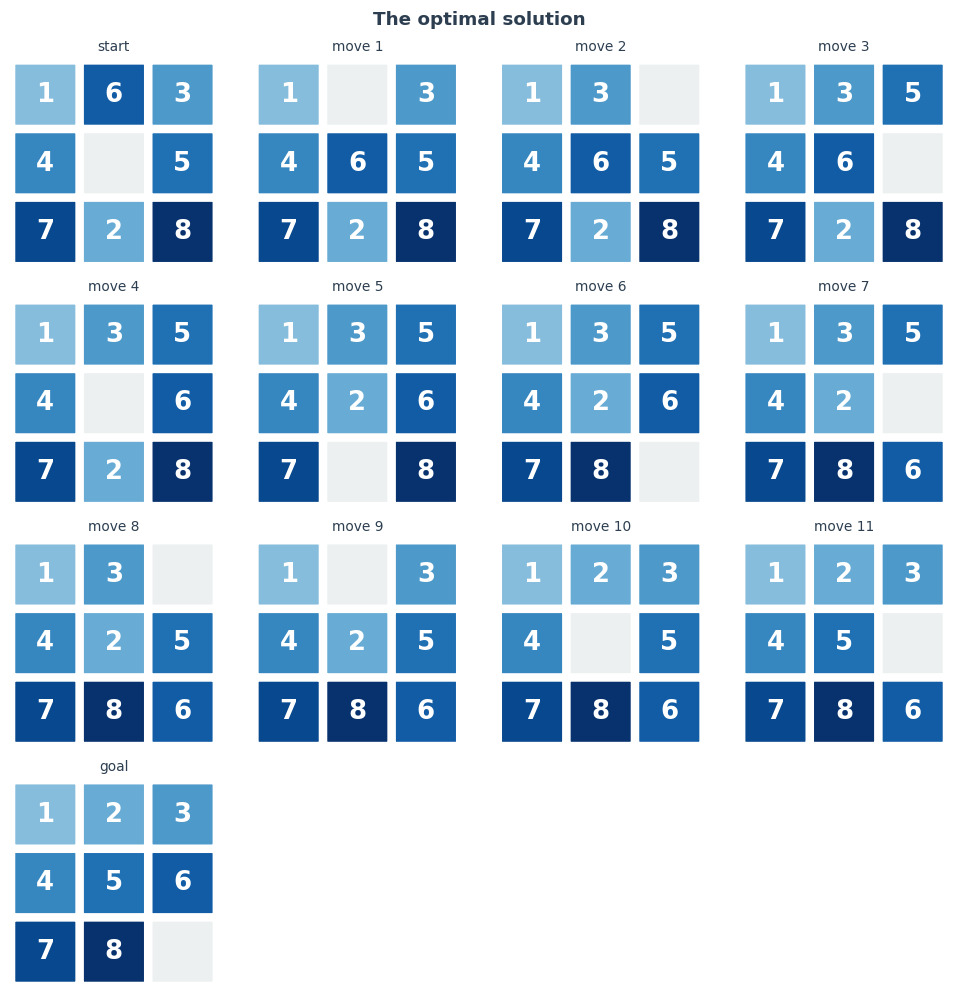

In [13]:
# Draw an 8-puzzle board
def draw_board(ax, state, title=""):
    for i, tile in enumerate(state):
        r, c = divmod(i, 3)
        face = "#ecf0f1" if tile == 0 else plt.cm.Blues(0.35 + 0.08 * tile)
        ax.add_patch(FancyBboxPatch((c + 0.06, 2 - r + 0.06), 0.88, 0.88, boxstyle="round,pad=0.02", fc=face, ec="white", lw=2))
        if tile:
            ax.text(c + 0.5, 2 - r + 0.5, str(tile), ha="center", va="center", fontsize=17, fontweight="bold", color="white")
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=9, color=DARK)

GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)
START = (1, 6, 3, 4, 0, 5, 7, 2, 8)
puzzle = PuzzleProblem(START, GOAL)

solution = bfs(puzzle)
print(f"BFS solved it in {solution['steps']} moves (the optimal number) after expanding {solution['expanded']:,} boards.")

boards = solution["path"]
cols = 4
rows_n = int(np.ceil(len(boards) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(9, 2.3 * rows_n))
for ax in axes.ravel():
    ax.axis("off")
for k, (ax, b) in enumerate(zip(axes.ravel(), boards)):
    draw_board(ax, b, "start" if k == 0 else "goal" if k == len(boards) - 1 else f"move {k}")
plt.suptitle("The optimal solution", color=DARK, fontweight="bold")
plt.tight_layout()
plt.show()

## 🏎️ Step 14: The race on the 8-puzzle
> 💡 All the algorithms try the same puzzle. We measure:
> - **steps**: length of the solution (fewer is better)
> - **expanded**: nodes examined (time)
> - **memory**: the most nodes held at once
> - **ms**: real time in milliseconds
>
> We use a logarithmic scale because the numbers are very different. Watch **DFS** (a huge, silly solution) and **IDDFS** (tiny memory).

    algorithm  found  steps   cost  expanded  memory     ms
          BFS   True     12     12      1026    1639   12.4
          DFS   True 103962 103962    152145  220523 3778.6
          UCS   True     12     12      1639    2726   48.1
        IDDFS   True     12     12      5375      13   58.3
Bidirectional   True     12     12       120     219    0.8


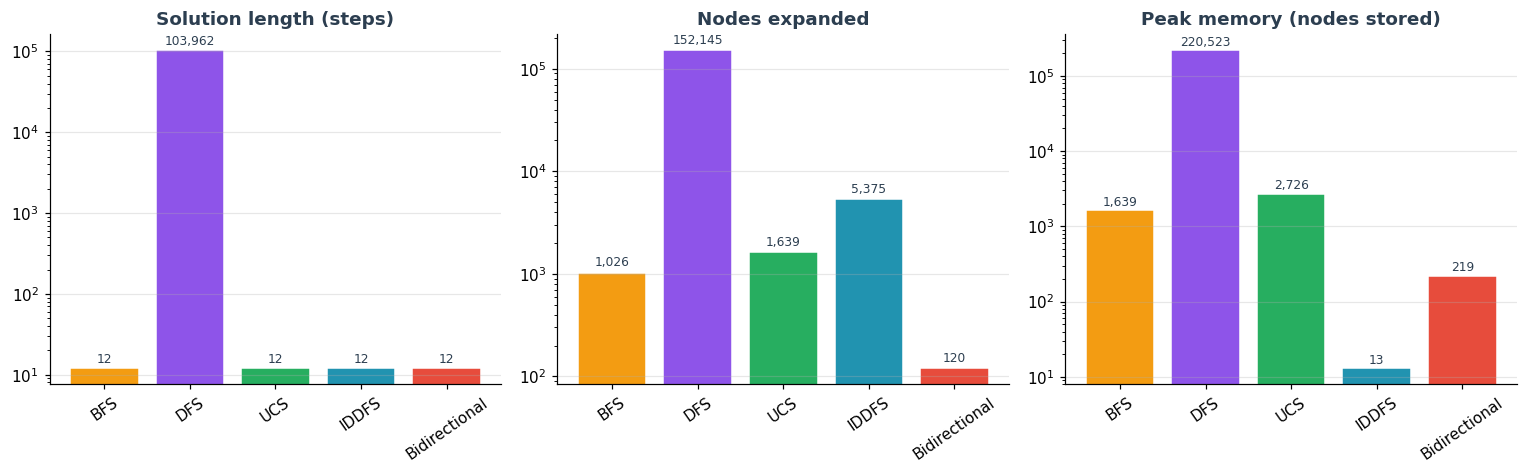

In [14]:
# Run every algorithm on the 8-puzzle (this may take a few seconds)
race = [bfs(puzzle), dfs(puzzle), ucs(puzzle), iddfs(puzzle), bidirectional(puzzle)]
race_table = results_table(race)
print(race_table.to_string(index=False))

names = [r["algorithm"] for r in race]
palette = [ORANGE, PURPLE, GREEN, BLUE, RED]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, key, title in zip(axes, ["steps", "expanded", "memory"],
                          ["Solution length (steps)", "Nodes expanded", "Peak memory (nodes stored)"]):
    values = [r[key] for r in race]
    bars = ax.bar(names, values, color=palette, edgecolor="white")
    ax.set_yscale("log")
    ax.set_title(title, color=DARK, fontweight="bold")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v * 1.15, f"{v:,}", ha="center", fontsize=8, color=DARK)
plt.tight_layout()
plt.show()

## 🧱 Step 15: Watch them explore a maze
> 💡 Each coloured cell was **explored**, and the colour shows **when** (dark = early, bright = late). Black cells are walls. The red line is the path found.
> - **BFS** spreads in a wave and explores almost everything nearby.
> - **DFS** snakes off in one direction and may find a path that wanders.
> - **Bidirectional** has two small waves that meet in the middle.

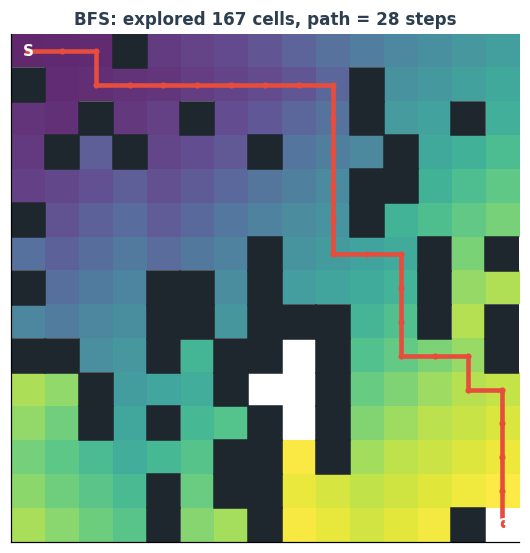

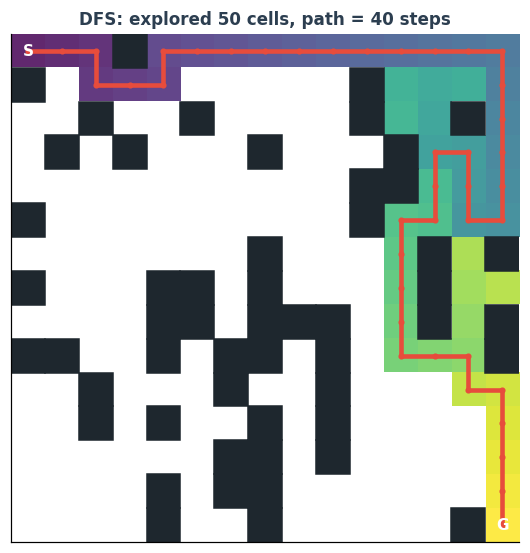

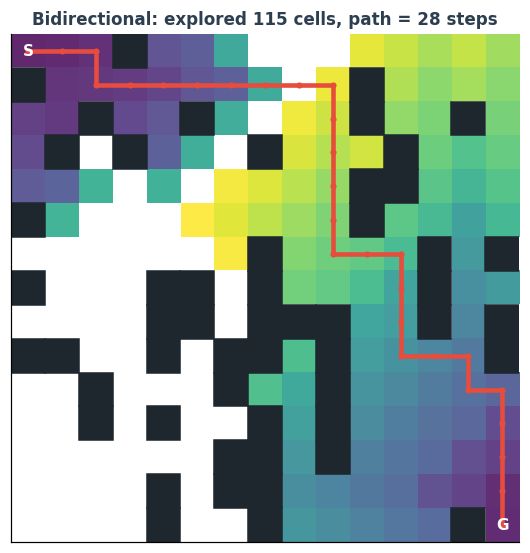

In [15]:
# Build a maze and show the exploration order of three algorithms
def make_maze(size=15, wall_chance=0.28):
    for seed in range(200):
        rng = random.Random(seed)
        walls = {(r, c) for r in range(size) for c in range(size)
                 if rng.random() < wall_chance and (r, c) not in [(0, 0), (size - 1, size - 1)]}
        p = GridProblem(size, walls, (0, 0), (size - 1, size - 1))
        if bfs(p)["found"]:
            return p

maze = make_maze()

def draw_maze(result):
    n = maze.size
    grid = np.full((n, n), np.nan)
    for k, (r, c) in enumerate(result["order"]):
        grid[r, c] = k / max(len(result["order"]) - 1, 1)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(np.zeros((n, n)), cmap="gray_r", vmin=0, vmax=1)               # white background
    for (r, c) in maze.walls:
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color="#1e272e"))
    ax.imshow(np.ma.masked_invalid(grid), cmap="viridis", alpha=0.85)
    path = result["path"]
    ax.plot([c for r, c in path], [r for r, c in path], color=RED, lw=3, marker="o", ms=3)
    ax.text(0, 0, "S", ha="center", va="center", color="white", fontweight="bold")
    ax.text(n - 1, n - 1, "G", ha="center", va="center", color="white", fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{result['algorithm']}: explored {result['expanded']} cells, path = {result['steps']} steps",
                 color=DARK, fontweight="bold", fontsize=11)
    plt.show()

for algo in (bfs, dfs, bidirectional):
    draw_maze(algo(maze))

## ⚠️ Limitations of blind search

| Limitation | What it means | Who fixed it |
|---|---|---|
| ❌ **Combinatorial explosion** | The number of states grows like `bᵈ`. The 8-puzzle has 181,440 reachable states, the 15-puzzle about 10 trillion | Informed search with heuristics (A\*, 1968) |
| ❌ **No sense of direction** | Blind search wastes time exploring in the wrong direction | Heuristic search, Greedy Best-First |
| ❌ **BFS memory** | It must store a whole level of the tree | Iterative Deepening, IDA\* |
| ❌ **DFS can give terrible paths** | The first solution found is not the best one | UCS or BFS when quality matters |
| ❌ **Needs a finite, known world** | States and actions must be listed explicitly | Planning languages, learning-based methods |

### 🧬 What it gave us
- The **problem formulation** (states, actions, goal, cost) that all later AI search uses
- The classic data structures for search: **queue, stack, priority queue**
- Dijkstra's algorithm, still used today in navigation, networks and games

## 📝 Summary
1. ✅ Many AI problems are **search problems**: find a path from a start state to a goal.
2. ✅ **BFS** finds the fewest steps; **DFS** uses little memory but can wander; **UCS** finds the cheapest path.
3. ✅ **DLS** limits the depth; **IDDFS** combines BFS's guarantees with DFS's tiny memory.
4. ✅ **Bidirectional** search meets in the middle and explores far less.
5. ✅ Blind search explodes on bigger problems. We need **hints**, which is the next chapter of the story.

## 🧪 Practice time
**Exercise 1.** On the Romania map, search from **Timisoara** to **Bucharest** with BFS and UCS. Are the routes the same?

**Exercise 2.** Use `depth_limited(map_problem, limit)` to find the **smallest limit** that reaches Bucharest from Arad. Which algorithm does this remind you of?

**Exercise 3.** Make the maze bigger (`make_maze(size=25)`) and compare how many cells BFS and Bidirectional explore.

<details>
<summary>👀 Click to see the solutions</summary>

```python
# Exercise 1
p = MapProblem(roads, "Timisoara", "Bucharest")
for algo in (bfs, ucs):
    r = algo(p)
    print(r["algorithm"], " → ".join(r["path"]), r["cost"], "km")
# BFS and UCS may choose different routes: BFS counts towns, UCS counts kilometres.

# Exercise 2
for limit in range(8):
    result, stats = depth_limited(map_problem, limit)
    if result != "cutoff":
        print("smallest limit:", limit)      # 3, this is exactly what IDDFS does automatically
        break

# Exercise 3
big = make_maze(size=25)
print(bfs(big)["expanded"], bidirectional(big)["expanded"])
# Bidirectional usually explores noticeably fewer cells.
```
</details>

## ⏭️ What's next in AI-Genesis
Blind search is slow because it has **no idea where the goal is**. Next: **A\* and heuristic search**, which uses a hint to head straight for the goal. 🚀